In [78]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

In [83]:
# The uncertainty factors, or dnb nodes
factortuples = [
    ("HHA", 3, ()),  # 0
    ("GER", 2, ()),  # 1
    ("OMA", 2, ()),  # 2

    ("PIS0", 4, ()), # 3
    ("PIH0", 5, (0,3,)), # 4
    ("LYS0", 4, (3,4,)), # 5
    ("LYH0", 7, (0,3,4,5,)), # 6
    ("AST0", 3, (1,2,4,6,)), # 7
    ("KUO0", 2, (3,4,5,6,)), # 8

    ("PISt", 4, (3,4,5,6,)), # 9
    ("PIHt", 5, (1,2,4,6,9,)), # 10
    ("LYSt", 4, (1,2,5,6,9,10,)), # 11
    ("LYHt", 7, (1,2,6,9,10,11,)), # 12
    ("ASTt", 3, (10,12,)), # 13
    ("KUOt", 2, (9,10,11,12,)), # 14
]
factors = [UncertaintyFactor(factor[0], factor[1], factor[2]) for factor in factortuples]

In [84]:
# marginals for each uncertainty factor
hha_mar = np.array([0.3, 0.4, 0.3])
ger_mar = np.array([0.7, 0.3])
oma_mar = np.array([0.5, 0.5])
pis_mar = np.array([0.0993, 0.388, 0.4343, 0.0784])
pih_mar = np.array([0.7467, 0.042, 0.14, 0.0663, 0.005])
lys_mar = np.array([0.9637, 0.0099, 0.0185, 0.0079])
lyh_mar = np.array([0.950, 0.031, 0.005, 0.01, 0.001, 0.003, 0])
ast_mar = np.array([0.5, 0.2, 0.3])
kuo_mar = np.array([0.00015, 1-0.00015])

In [89]:
df = pd.read_csv("ci-data/cross-impact-healthcare-sheet.csv")
df = df.iloc[8:, 3:]
df = df.astype(float)
ls = list(map(lambda x : x[1], factortuples))
print(ls)
lo = []
for i, l in enumerate(ls):
    lo.append(sum(ls[:i]))
print(lo)
print("---")

cross_impacts = {}
for fi, factor in enumerate(factortuples):
    for parent_index in factor[2]:
        print(f"({parent_index}, {fi})")
        factor_dim = factor[1]
        parent_dim = factortuples[parent_index][1]
        #cross_impacts[(parent_index, fi)] = np.zeros((parent_dim, factor_dim))
        cross_impacts[(parent_index, fi)] = np.array(df.iloc[lo[parent_index]:lo[parent_index]+ls[parent_index],lo[fi]:lo[fi]+ls[fi]])
        print(cross_impacts[parent_index, fi])

[3, 2, 2, 4, 5, 4, 7, 3, 2, 4, 5, 4, 7, 3, 2]
[0, 3, 5, 7, 11, 16, 20, 27, 30, 32, 36, 41, 45, 52, 55]
---
(0, 4)
[[ 2. -2. -2. -2. -2.]
 [ 0.  0.  0.  0.  0.]
 [-2.  2.  2.  2.  2.]]
(3, 4)
[[ 3. -3. -3. -3. -3.]
 [ 2. -2. -2. -2. -2.]
 [-2.  2.  2.  1.  1.]
 [-3.  2.  2.  3.  3.]]
(3, 5)
[[3. 2. 1. 0.]
 [2. 3. 2. 1.]
 [1. 2. 3. 2.]
 [0. 1. 2. 3.]]
(4, 5)
[[1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
(0, 6)
[[ 2. -2. -2. -2. -2. -2. -2.]
 [ 0.  0.  0.  0.  0.  0.  0.]
 [-2.  2.  2.  2.  2.  2.  2.]]
(3, 6)
[[ 2. -2. -2. -2. -2. -2. -2.]
 [ 1. -1. -1. -1. -1. -1. -1.]
 [-1.  1.  1.  1.  1.  1.  1.]
 [-2.  2.  2.  2.  2.  2.  2.]]
(4, 6)
[[ 1.  0.  0. -1. -1. -1. -1.]
 [ 0.  1.  0.  0.  0.  0.  0.]
 [ 0.  1.  1.  0. -1.  0.  0.]
 [ 0.  0.  0.  0.  0.  1.  1.]
 [ 0.  0.  0.  0.  0.  1.  1.]]
(5, 6)
[[ 3.  1.  1. -2. -3. -3. -3.]
 [ 1.  1.  1. -1. -2. -3. -3.]
 [-1.  2.  3.  3.  3.  2.  1.]
 [-3. -3.  3.  3.  3.  1. -1.]]
(1, 7)
[[ 1.  0. -1.]
 [-1.  0.  1.]]

In [90]:
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        hha_mar,
        ger_mar,
        oma_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        kuo_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        kuo_mar,
    ],
    cross_impacts=cross_impacts,
)
built = build_network(network, mode="independent", initial_joint=None)

/home/vili/bayes-learning/cross_impact/fitting.py:74: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(verbose=True)


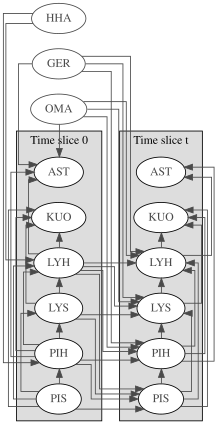

In [91]:
from cross_impact.pyagrum_export import to_pyagrum

bn = to_pyagrum(built)
gdyn.showTimeSlices(bn)

# HUOMIO! Lisää noodi, joka käsittelee kuolleen erikseen! eli siis kaikki tuo on ehdollistettu sillä, että henkilö on elossa.

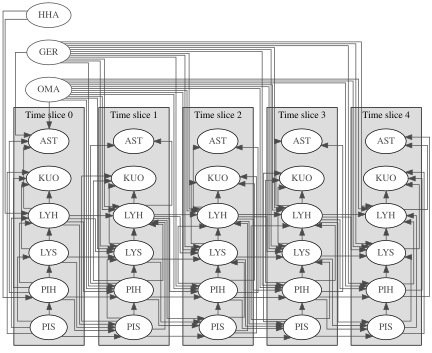

In [92]:
T = 5
dbn = gdyn.unroll2TBN(bn, T)
gdyn.showTimeSlices(dbn)

In [94]:
ie = gum.LazyPropagation(dbn)
gnb.sideBySide(ie.posterior("PIS3"), ie.posterior("PIS4"), ie.posterior("KUO3"))
for i in range(4):
    ie.setEvidence({"PIS3": i})
    gnb.sideBySide(ie.posterior("PIS3"), ie.posterior("PIS4"), ie.posterior("KUO3"))